# 03.3 — Calibração e Testes Estatísticos
**Depende de:** 03.2 executado antes (artefatos em out/artifacts/)
**Salva em:** out/artifacts/ e out/03.3_calibracao/

In [11]:
from __future__ import annotations

import json
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)

# ── Idioma / Language ─────────────────────────────────────────────────────────
LANG = "pt"  # "pt" | "en"  ← única linha a alterar para mudar idioma

_T = {
    "pt": {
        # ROC / PR curves
        "roc_xlabel":       "1 - Especificidade (FPR)",
        "roc_ylabel":       "Sensibilidade (TPR)",
        "roc_title":        "Curva ROC — Conjunto de Teste",
        "pr_xlabel":        "Recall (Sensibilidade)",
        "pr_ylabel":        "Precisão (PPV)",
        "pr_title":         "Curva Precision-Recall — Conjunto de Teste",
        "pr_prev_lbl":      "Prevalência={v:.2f}",
        "roc_pr_suptitle":  "Discriminação — Conjunto de Teste",
        # Calibration
        "cal_title_fmt":    "Calibração — {nome}",
        "cal_xlabel":       "Probabilidade prevista",
        "cal_ylabel":       "Fração positivos observados",
        "cal_suptitle":     "Curvas de Calibração — Conjunto de Teste",
        "cal_smooth_perf":  "Perfeita calibração",
        "cal_smooth_xlabel":"Probabilidade Prevista",
        "cal_smooth_ylabel":"Proporção Observada",
        "cal_smooth_title": "Calibração Suavizada (LOWESS) — Conjunto de Teste",
        # Post-calibration
        "postcal_before":   "Antes",
        "postcal_after_fmt":"Após ({metodo})",
        "postcal_perfect":  "Perfeito",
        "postcal_xlabel":   "Prob. prevista",
        "postcal_ylabel":   "Fração observada",
        "postcal_suptitle": "Calibração — Antes vs Depois (Platt/Isotonic)",
        # Confusion matrices
        "cm_neg_pred":      "Neg (pred)",
        "cm_pos_pred":      "Pos (pred)",
        "cm_neg_real":      "Neg (real)",
        "cm_pos_real":      "Pos (real)",
        "cm_fixo_title_fmt":"Sens={sens:.1%}  Spec={spec:.1%}  PPV={ppv:.1%}  NPV={npv:.1%}",
        "cm_fixo_suptitle": "Matrizes de Confusão — Threshold Fixo = 0.30\n(Desfecho: retorno não planejado em 30 dias)",
        "cm_youden_title_fmt":"Sens={sens:.1%}  Spec={spec:.1%}  PPV={ppv:.1%}  NPV={npv:.1%}",
        "cm_youden_suptitle":"Matrizes de Confusão — Threshold Ótimo (Youden J)\n(Desfecho: retorno não planejado em 30 dias)",
    },
    "en": {
        # ROC / PR curves
        "roc_xlabel":       "1 - Specificity (FPR)",
        "roc_ylabel":       "Sensitivity (TPR)",
        "roc_title":        "ROC Curve — Test Set",
        "pr_xlabel":        "Recall (Sensitivity)",
        "pr_ylabel":        "Precision (PPV)",
        "pr_title":         "Precision-Recall Curve — Test Set",
        "pr_prev_lbl":      "Prevalence={v:.2f}",
        "roc_pr_suptitle":  "Model Discrimination — Test Set",
        # Calibration
        "cal_title_fmt":    "Calibration — {nome}",
        "cal_xlabel":       "Predicted probability",
        "cal_ylabel":       "Observed positive fraction",
        "cal_suptitle":     "Calibration Curves — Test Set",
        "cal_smooth_perf":  "Perfect calibration",
        "cal_smooth_xlabel":"Predicted Probability",
        "cal_smooth_ylabel":"Observed Proportion",
        "cal_smooth_title": "Smoothed Calibration (LOWESS) — Test Set",
        # Post-calibration
        "postcal_before":   "Before",
        "postcal_after_fmt":"After ({metodo})",
        "postcal_perfect":  "Perfect",
        "postcal_xlabel":   "Predicted prob.",
        "postcal_ylabel":   "Observed fraction",
        "postcal_suptitle": "Calibration — Before vs After (Platt/Isotonic)",
        # Confusion matrices
        "cm_neg_pred":      "Neg (pred)",
        "cm_pos_pred":      "Pos (pred)",
        "cm_neg_real":      "Neg (real)",
        "cm_pos_real":      "Pos (real)",
        "cm_fixo_title_fmt":"Sens={sens:.1%}  Spec={spec:.1%}  PPV={ppv:.1%}  NPV={npv:.1%}",
        "cm_fixo_suptitle": "Confusion Matrices — Fixed Threshold = 0.30\n(Outcome: unplanned 30-day readmission)",
        "cm_youden_title_fmt":"Sens={sens:.1%}  Spec={spec:.1%}  PPV={ppv:.1%}  NPV={npv:.1%}",
        "cm_youden_suptitle":"Confusion Matrices — Optimal Threshold (Youden J)\n(Outcome: unplanned 30-day readmission)",
    },
}
T = _T[LANG]

# Paths
ROOT     = Path("..").resolve()
DATA_DIR = ROOT / "data"
OUT_DIR  = ROOT / "out" / "03.3_calibracao"
PLOT_DIR = OUT_DIR / "plots"
ART_DIR  = ROOT / "out" / "artifacts"   # shared state between sub-files

OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
ART_DIR.mkdir(parents=True, exist_ok=True)

## Carregar Artefatos

In [12]:
with open(ART_DIR / "splits.pkl", "rb") as f:
    _splits = pickle.load(f)

df_train  = _splits["df_train"]
df_valid  = _splits["df_valid"]
df_test   = _splits["df_test"]
y_train   = _splits["y_train"]
y_valid   = _splits["y_valid"]
y_test    = _splits["y_test"]
X_train_t = _splits["X_train_t"]
X_valid_t = _splits["X_valid_t"]
X_test_t  = _splits["X_test_t"]
X_train   = _splits["X_train"]
X_valid   = _splits["X_valid"]
X_test    = _splits["X_test"]

with open(ART_DIR / "features.json", "r", encoding="utf-8") as f:
    _feat = json.load(f)
FEATURES         = _feat["FEATURES"]
TARGET_PRINCIPAL = _feat["TARGET_PRINCIPAL"]
THRESHOLD        = _feat["THRESHOLD"]
TARGETS          = _feat["TARGETS"]

# _Dummy precisa existir neste escopo antes de unpickle (foi serializado como __main__._Dummy)
class _Dummy:
    def __init__(self, prev=0.5):
        self.prev = prev
    def predict_proba(self, X):
        n = len(X) if hasattr(X, "__len__") else X.shape[0]
        return np.column_stack([1 - self.prev * np.ones(n),
                                       self.prev * np.ones(n)])

with open(ART_DIR / "modelos_fit.pkl", "rb") as f:
    modelos_fit = pickle.load(f)

with open(ART_DIR / "probs_teste.pkl", "rb") as f:
    probs_teste = pickle.load(f)

with open(ART_DIR / "thresholds_opt.json", "r", encoding="utf-8") as f:
    threshold_youden_por_modelo = json.load(f)

with open(ART_DIR / "preprocessor.pkl", "rb") as f:
    _preproc_d = pickle.load(f)
preproc = _preproc_d["preproc"]

CORES = ["steelblue", "darkorange", "seagreen", "firebrick",
         "mediumpurple", "saddlebrown", "deeppink", "teal"]

print(f"Modelos carregados: {list(modelos_fit.keys())}")

# ── Funções auxiliares (auto-contidas) ─────────────────────────────────────
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    from lightgbm import LGBMClassifier
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

try:
    from catboost import CatBoostClassifier
    HAS_CAT = True
except ImportError:
    HAS_CAT = False


def _predict_proba(nome, clf, X_raw, X_transformed):
    if nome == "M5_CAT" and HAS_CAT:
        return clf.predict_proba(X_raw)[:, 1]
    try:
        return clf.predict_proba(X_transformed)[:, 1]
    except Exception:
        return clf.predict_proba(X_raw)[:, 1]


def ece_score(y_true, y_prob, n_bins=10):
    """Expected Calibration Error."""
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() == 0:
            continue
        acc  = y_true[mask].mean()
        conf = y_prob[mask].mean()
        ece += mask.sum() / len(y_true) * abs(acc - conf)
    return ece


def youden_threshold(y_true, y_prob):
    from sklearn.metrics import roc_curve
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    j = tpr - fpr
    return float(thresholds[np.argmax(j)])


def hosmer_lemeshow(y_true, y_prob, n_bins=10):
    from scipy import stats as scipy_stats
    df_hl = pd.DataFrame({"y": y_true, "p": y_prob})
    df_hl["grupo"] = pd.qcut(df_hl["p"], q=n_bins, duplicates="drop", labels=False)
    obs  = df_hl.groupby("grupo")["y"].sum()
    exp  = df_hl.groupby("grupo")["p"].sum()
    n_g  = df_hl.groupby("grupo").size()
    hl   = ((obs - exp)**2 / (exp * (1 - exp/n_g))).sum()
    p    = scipy_stats.chi2.sf(hl, df=n_bins - 2)
    return float(hl), float(p)


from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    roc_curve, precision_recall_curve,
)

## 9. Curvas ROC e PR

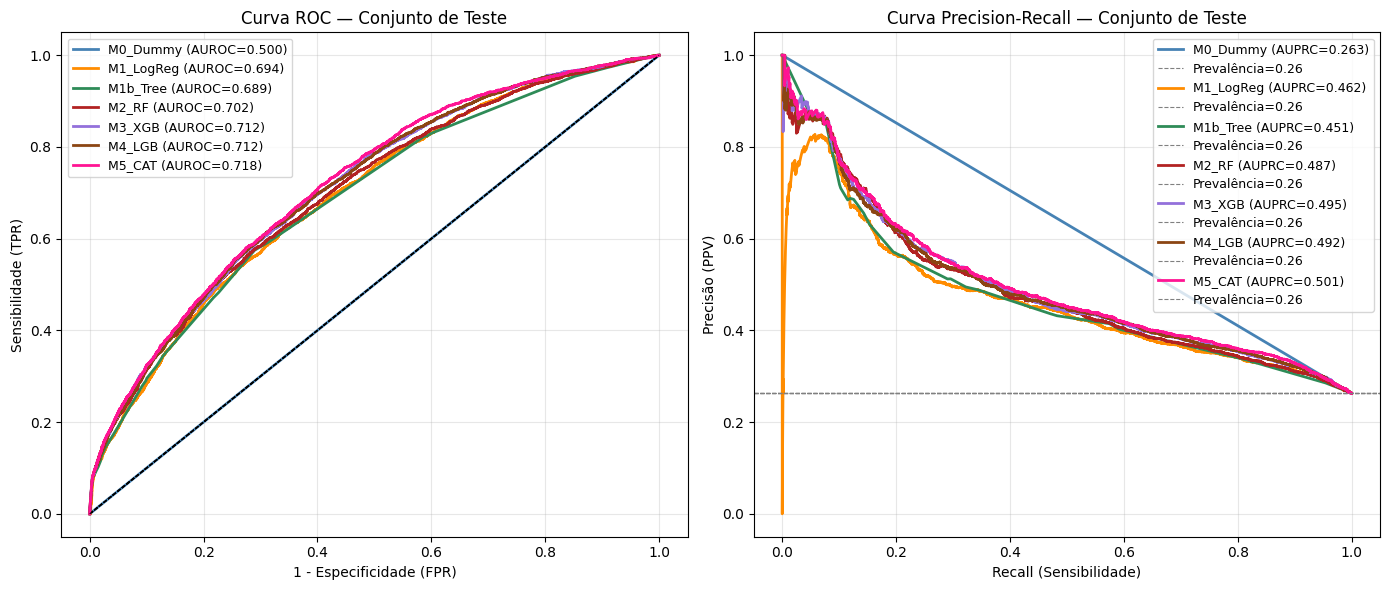

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, curve_fn in zip(axes, ["roc", "pr"]):
    for (nome, clf), cor in zip(modelos_fit.items(), CORES):
        prob = _predict_proba(nome, clf, X_test, X_test_t)
        if curve_fn == "roc":
            fpr, tpr, _ = roc_curve(y_test, prob)
            auc = roc_auc_score(y_test, prob)
            ax.plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUROC={auc:.3f})")
            ax.plot([0,1],[0,1], "k--", lw=0.8)
            ax.set_xlabel(T["roc_xlabel"]); ax.set_ylabel(T["roc_ylabel"])
            ax.set_title(T["roc_title"])
        else:
            prec, rec, _ = precision_recall_curve(y_test, prob)
            ap = average_precision_score(y_test, prob)
            ax.plot(rec, prec, color=cor, lw=2, label=f"{nome} (AUPRC={ap:.3f})")
            baseline = y_test.mean()
            ax.axhline(baseline, color="gray", ls="--", lw=0.8, label=T["pr_prev_lbl"].format(v=baseline))
            ax.set_xlabel(T["pr_xlabel"]); ax.set_ylabel(T["pr_ylabel"])
            ax.set_title(T["pr_title"])
        ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / "01_roc_pr_curves.png", dpi=150)
plt.show()

## 10. Calibração

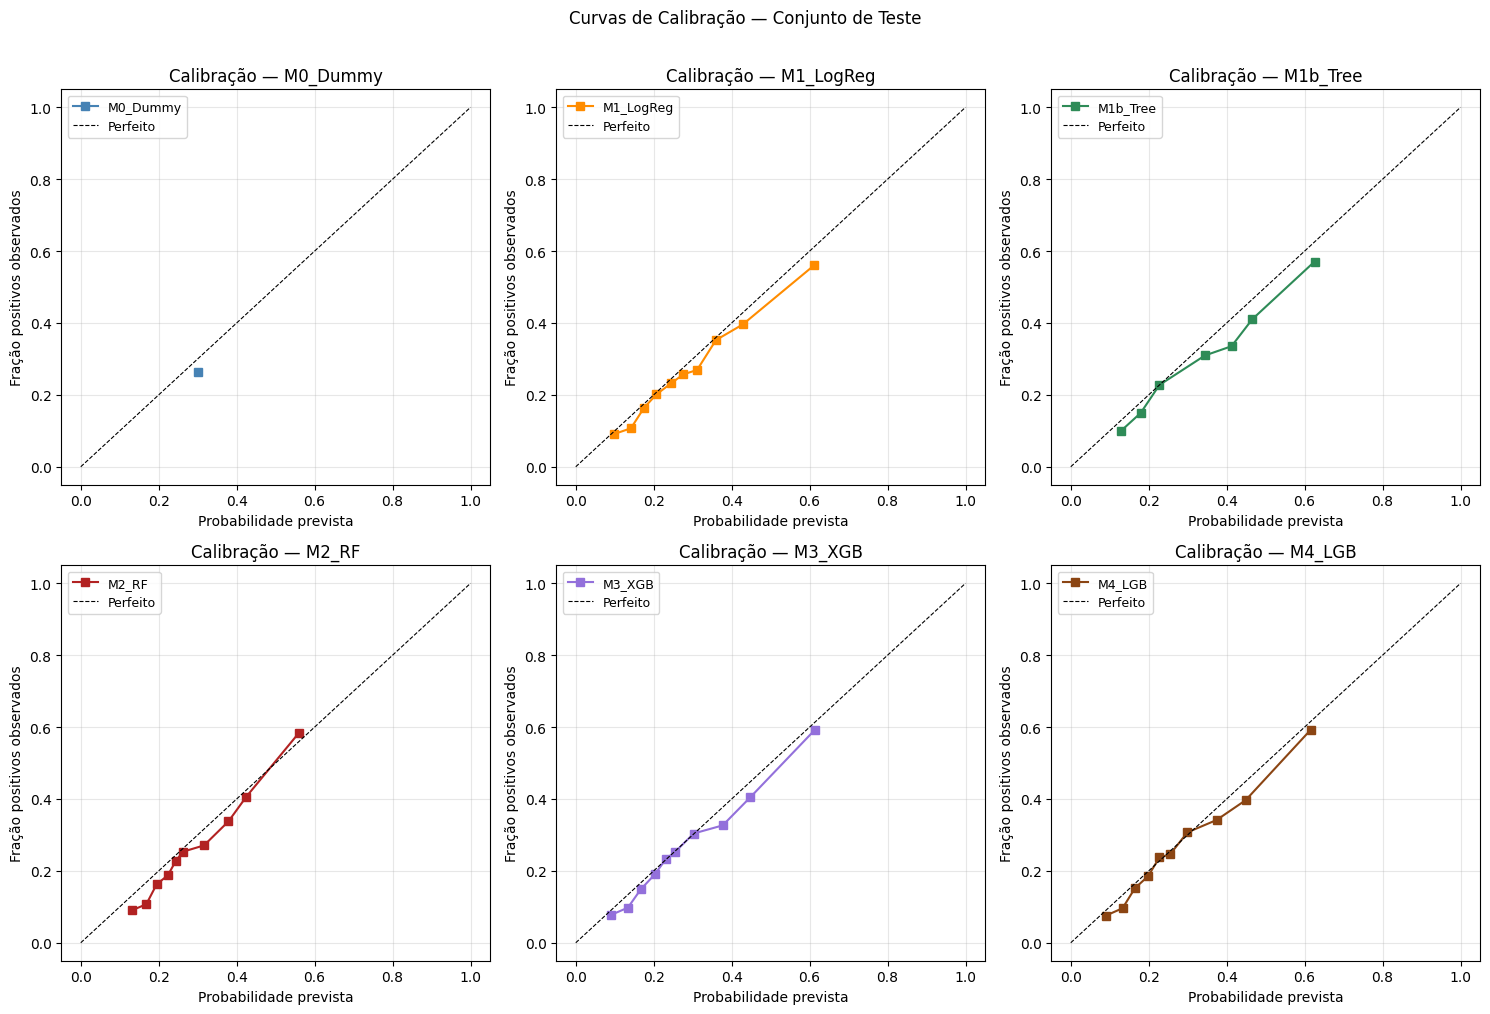

In [25]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, (nome, clf), cor in zip(axes, modelos_fit.items(), CORES):
    prob = _predict_proba(nome, clf, X_test, X_test_t)
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "s-", color=cor, label=nome)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Perfeito")
    ax.set_title(T["cal_title_fmt"].format(nome=nome))
    ax.set_xlabel(T["cal_xlabel"])
    ax.set_ylabel(T["cal_ylabel"])
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

for j in range(len(modelos_fit), len(axes)):
    axes[j].axis("off")

plt.suptitle(T["cal_suptitle"], fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR / "02_calibracao.png", dpi=150, bbox_inches="tight")
plt.show()

## 10b. Calibration Slope + Intercept

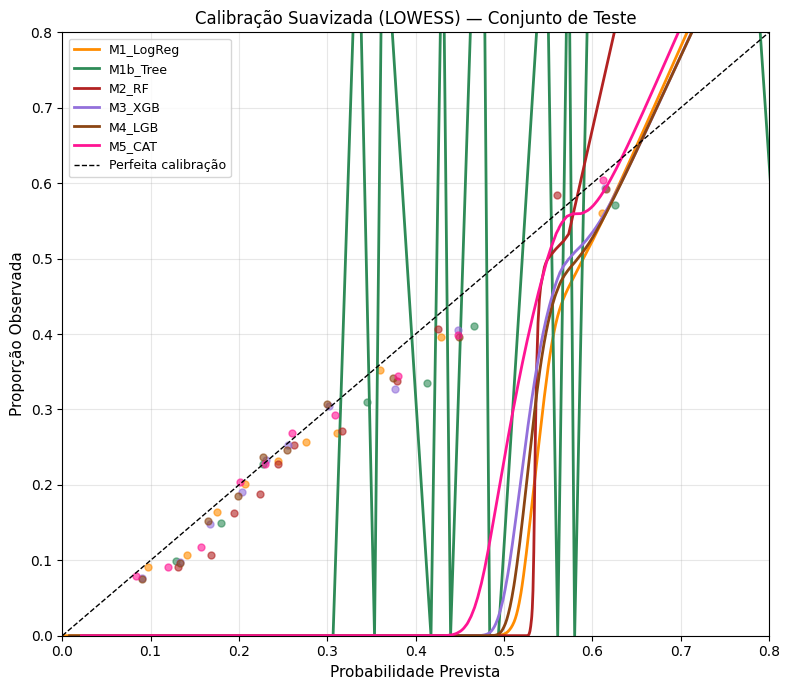

In [15]:
import statsmodels.api as sm_cal

rows_calslope = []
print("\n" + "=" * 70)
print("CALIBRATION SLOPE & INTERCEPT (TRIPOD+AI)")
print("=" * 70)
print(f"{'Modelo':20s}  {'Slope':>8}  {'Intercept':>10}  {'Brier':>8}  {'ECE':>8}")

for nome, clf in modelos_fit.items():
    prob = _predict_proba(nome, clf, X_test, X_test_t)
    prob = np.clip(prob, 1e-8, 1 - 1e-8)
    logit_p = np.log(prob / (1 - prob))

    try:
        X_cs = sm_cal.add_constant(logit_p)
        fit_cs = sm_cal.Logit(y_test, X_cs).fit(disp=False, maxiter=200)
        intercept = fit_cs.params[0]
        slope     = fit_cs.params[1]
    except Exception:
        intercept, slope = np.nan, np.nan

    brier_val = brier_score_loss(y_test, prob)
    ece_val   = ece_score(y_test, prob)

    rows_calslope.append({
        "modelo": nome,
        "cal_slope": round(slope, 4) if not np.isnan(slope) else np.nan,
        "cal_intercept": round(intercept, 4) if not np.isnan(intercept) else np.nan,
        "brier": round(brier_val, 4),
        "ece": round(ece_val, 4),
    })
    print(f"  {nome:20s}  {slope:>8.4f}  {intercept:>10.4f}  {brier_val:>8.4f}  {ece_val:>8.4f}")

pd.DataFrame(rows_calslope).to_csv(OUT_DIR / "calibration_slope_intercept.csv", index=False)

# ── Calibration Plot Suavizado (LOESS) ─────────────────────────────────────
fig_cs, ax_cs = plt.subplots(figsize=(8, 7))
modelos_plot_names = [n for n in modelos_fit if n != "M0_Dummy"]

for nome, cor in zip(modelos_plot_names, CORES[1:]):
    clf = modelos_fit[nome]
    prob = _predict_proba(nome, clf, X_test, X_test_t)
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=10, strategy="quantile")
    ax_cs.plot(mean_pred, frac_pos, "o", color=cor, alpha=0.6, markersize=5)
    try:
        from statsmodels.nonparametric.smoothers_lowess import lowess
        sorted_idx = np.argsort(prob)
        smooth = lowess(y_test[sorted_idx], prob[sorted_idx], frac=0.3, return_sorted=True)
        ax_cs.plot(smooth[:, 0], smooth[:, 1], color=cor, lw=2, label=nome)
    except Exception:
        ax_cs.plot(mean_pred, frac_pos, "-", color=cor, lw=2, label=nome)

ax_cs.plot([0, 1], [0, 1], "k--", lw=1, label=T["cal_smooth_perf"])
ax_cs.set_xlabel(T["cal_smooth_xlabel"], fontsize=11)
ax_cs.set_ylabel(T["cal_smooth_ylabel"], fontsize=11)
ax_cs.set_title(T["cal_smooth_title"], fontsize=12)
ax_cs.legend(fontsize=9); ax_cs.grid(alpha=0.3)
ax_cs.set_xlim(0, 0.8); ax_cs.set_ylim(0, 0.8)
plt.tight_layout()
plt.savefig(PLOT_DIR / "02c_calibracao_suavizada.png", dpi=150)
plt.show(); plt.close()
print("  Gerado: plots/02c_calibracao_suavizada.png")

## 18. Testes Estatísticos — DeLong / McNemar / Hosmer-Lemeshow

In [16]:
from scipy import stats as scipy_stats

def delong_test(y_true, prob_a, prob_b):
    """Teste DeLong para comparação de duas AUROCs. DeLong et al. (1988)."""
    def _wilcoxon_components(y, prob):
        pos = prob[y == 1]
        neg = prob[y == 0]
        n1, n0 = len(pos), len(neg)
        V10 = np.array([np.mean(p > neg) + 0.5 * np.mean(p == neg) for p in pos])
        V01 = np.array([np.mean(p < pos) + 0.5 * np.mean(p == pos) for p in neg])
        return V10, V01, n1, n0

    V10a, V01a, n1, n0 = _wilcoxon_components(y_true, prob_a)
    V10b, V01b, _,  _  = _wilcoxon_components(y_true, prob_b)
    theta_a = V10a.mean(); theta_b = V10b.mean()
    S10 = np.cov(V10a, V10b); S01 = np.cov(V01a, V01b)
    var   = S10[0,0]/n1 + S01[0,0]/n0
    var_b = S10[1,1]/n1 + S01[1,1]/n0
    cov   = S10[0,1]/n1 + S01[0,1]/n0
    var_diff = var + var_b - 2*cov
    if var_diff <= 0: return 0.0, 1.0
    z = (theta_a - theta_b) / np.sqrt(var_diff)
    p = 2 * (1 - scipy_stats.norm.cdf(abs(z)))
    return float(z), float(p)


modelo_ref = max(probs_teste, key=lambda n: roc_auc_score(y_test, probs_teste[n])
                 if y_test.sum() > 0 else 0)
print(f"\nModelo de referência (melhor AUROC): {modelo_ref}")

n_comparacoes = len(probs_teste) - 1
alpha_bonf = 0.05 / max(n_comparacoes, 1)

rows_delong = []
print(f"\nTeste DeLong vs {modelo_ref} (α Bonferroni = {alpha_bonf:.4f}):")
print(f"{'Modelo':20s}  {'AUROC':>8}  {'∆AUROC':>8}  {'Z':>7}  {'p-valor':>9}  {'Sig*':>6}")
print("-" * 70)
for nome in probs_teste:
    if nome == modelo_ref: continue
    auroc_ref  = roc_auc_score(y_test, probs_teste[modelo_ref])
    auroc_nome = roc_auc_score(y_test, probs_teste[nome])
    z, p = delong_test(y_test, probs_teste[modelo_ref], probs_teste[nome])
    sig = "***" if p < alpha_bonf else ("*" if p < 0.05 else "ns")
    rows_delong.append({"modelo": nome, "auroc": round(auroc_nome, 4),
                        "delta_auroc": round(auroc_nome - auroc_ref, 4),
                        "z": round(z, 3), "p_valor": round(p, 4),
                        "significativo_bonf": p < alpha_bonf})
    print(f"  {nome:20s}  {auroc_nome:>8.4f}  {auroc_nome-auroc_ref:>+8.4f}"
          f"  {z:>7.3f}  {p:>9.4f}  {sig:>6}")
pd.DataFrame(rows_delong).to_csv(OUT_DIR / "testes_delong.csv", index=False)

from sklearn.metrics import confusion_matrix
print(f"\nTeste McNemar — concordância de predições (threshold 0.30):")
preds = {n: (probs_teste[n] >= 0.30).astype(int) for n in probs_teste}
modelos_list = list(probs_teste.keys())
rows_mcnemar = []
for i in range(len(modelos_list)):
    for j in range(i+1, len(modelos_list)):
        na, nb = modelos_list[i], modelos_list[j]
        pa, pb = preds[na], preds[nb]
        b = ((pa == y_test) & (pb != y_test)).sum()
        c = ((pb == y_test) & (pa != y_test)).sum()
        if b + c == 0: continue
        chi2 = (abs(b - c) - 1)**2 / (b + c)
        p    = scipy_stats.chi2.sf(chi2, df=1)
        rows_mcnemar.append({"par": f"{na} vs {nb}", "b": b, "c": c,
                              "chi2": round(chi2,3), "p_valor": round(p,4)})
pd.DataFrame(rows_mcnemar).to_csv(OUT_DIR / "testes_mcnemar.csv", index=False)

print(f"\nTeste Hosmer-Lemeshow (p > 0.05 indica boa calibração):")
rows_hl = []
for nome in probs_teste:
    hl, p = hosmer_lemeshow(y_test, probs_teste[nome])
    rows_hl.append({"modelo": nome, "hl_chi2": round(hl,3),
                    "p_valor": round(p,4), "bem_calibrado": p > 0.05})
    status = "Sim" if p > 0.05 else "Nao"
    print(f"  {nome:20s}  HL={hl:>8.3f}  p={p:>8.4f}  Calibrado={status}")
pd.DataFrame(rows_hl).to_csv(OUT_DIR / "testes_hosmer_lemeshow.csv", index=False)

## 18b. Pós-Calibração (Platt Scaling + Isotonic)

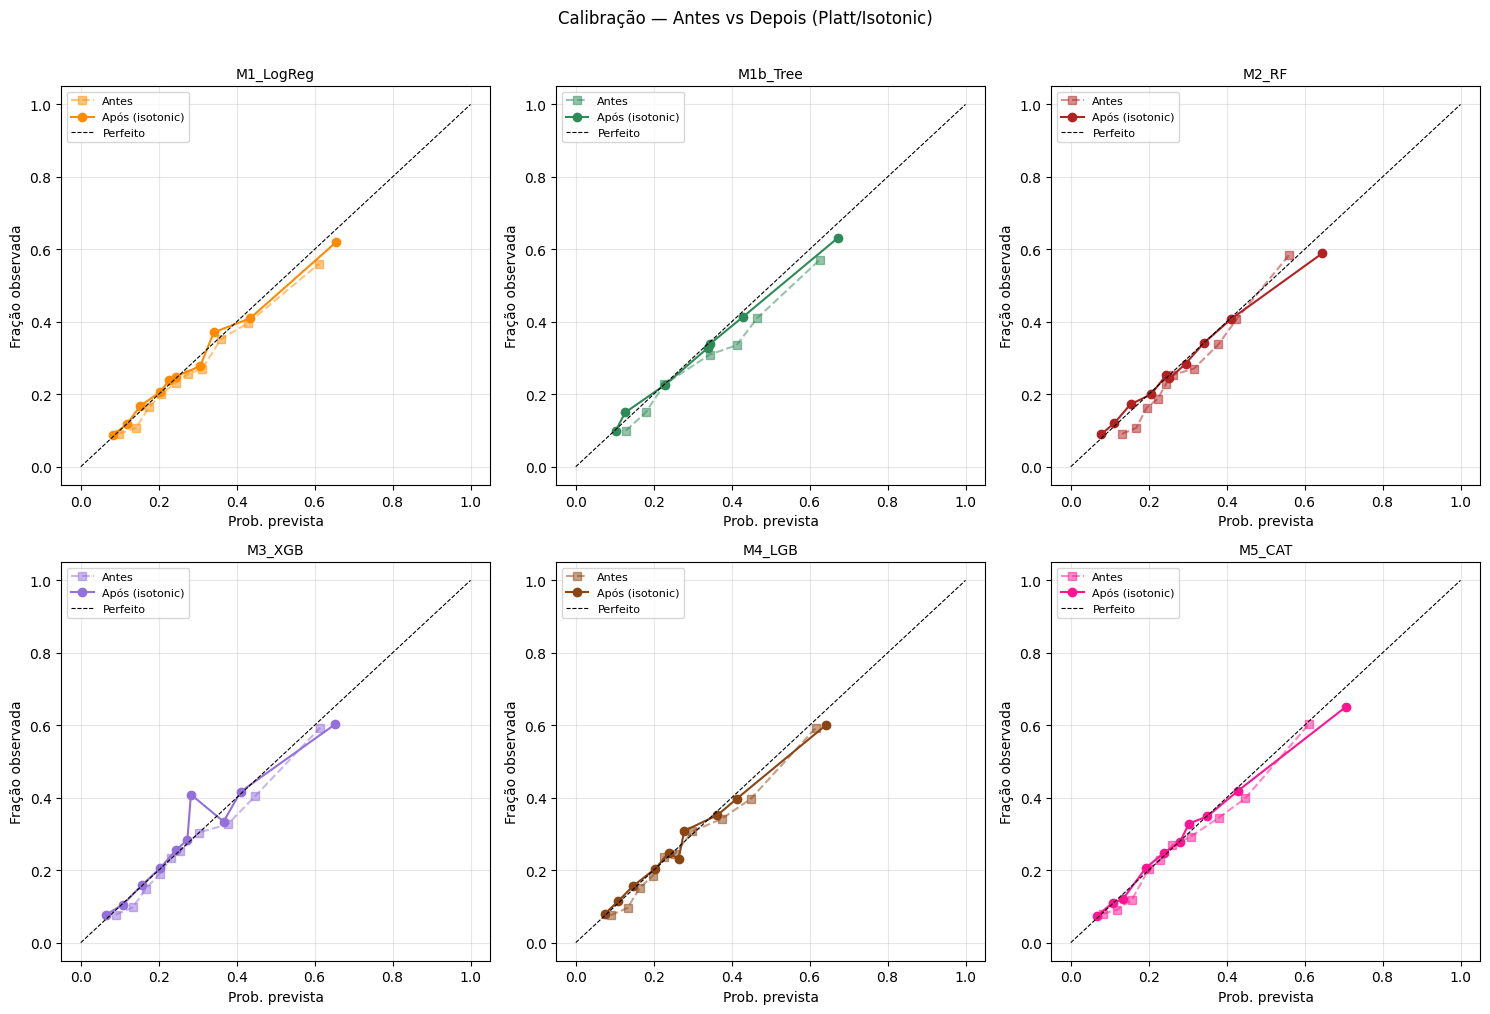

In [26]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression as _LR_Cal

print("\n" + "=" * 70)
print("PÓS-CALIBRAÇÃO — Platt Scaling (sigmoid) + Isotonic Regression")
print("=" * 70)

probs_valid = {}
for nome, clf in modelos_fit.items():
    probs_valid[nome] = _predict_proba(nome, clf, X_valid, X_valid_t)

calibradores = {}
probs_teste_cal = {}
metodo_escolhido = {}

for nome in modelos_fit:
    p_val = probs_valid[nome]
    p_tst = probs_teste[nome]

    lr_platt = _LR_Cal(solver="lbfgs", max_iter=1000)
    lr_platt.fit(p_val.reshape(-1, 1), y_valid)
    p_tst_platt = lr_platt.predict_proba(p_tst.reshape(-1, 1))[:, 1]

    iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip")
    iso.fit(p_val, y_valid)
    p_tst_iso = iso.predict(p_tst)

    brier_platt = brier_score_loss(y_test, p_tst_platt)
    brier_iso   = brier_score_loss(y_test, p_tst_iso)

    if brier_platt <= brier_iso:
        probs_teste_cal[nome] = p_tst_platt; metodo_escolhido[nome] = "platt"
    else:
        probs_teste_cal[nome] = p_tst_iso; metodo_escolhido[nome] = "isotonic"

    calibradores[nome] = {"platt": lr_platt, "isotonic": iso}

print(f"\nTeste Hosmer-Lemeshow PÓS-CALIBRAÇÃO:")
rows_hl_cal = []
for nome in probs_teste_cal:
    hl, p = hosmer_lemeshow(y_test, probs_teste_cal[nome])
    brier_antes  = brier_score_loss(y_test, probs_teste[nome])
    brier_depois = brier_score_loss(y_test, probs_teste_cal[nome])
    status = "Sim" if p > 0.05 else "Nao"
    rows_hl_cal.append({"modelo": nome, "metodo": metodo_escolhido[nome],
                        "hl_chi2": round(hl, 3), "p_valor": round(p, 4),
                        "bem_calibrado": p > 0.05,
                        "brier_antes": round(brier_antes, 4),
                        "brier_depois": round(brier_depois, 4)})
    print(f"  {nome:20s}  {metodo_escolhido[nome]:>10}  HL={hl:>8.3f}  p={p:>8.4f}  "
          f"Calibrado={status}  Brier antes={brier_antes:.4f}  depois={brier_depois:.4f}")

pd.DataFrame(rows_hl_cal).to_csv(OUT_DIR / "testes_hosmer_lemeshow_calibrado.csv", index=False)

n_modelos_cal = len([n for n in modelos_fit if n != "M0_Dummy"])
fig_cal, axes_cal = plt.subplots(2, 3, figsize=(15, 10))
axes_cal = axes_cal.flatten()

idx_ax = 0
for (nome, clf), cor in zip(modelos_fit.items(), CORES):
    if nome == "M0_Dummy":
        continue
    ax = axes_cal[idx_ax]; idx_ax += 1
    prob_orig = probs_teste[nome]
    frac_orig, mean_orig = calibration_curve(y_test, prob_orig, n_bins=10, strategy="quantile")
    ax.plot(mean_orig, frac_orig, "s--", color=cor, alpha=0.5, label=T["postcal_before"])
    prob_cal = probs_teste_cal[nome]
    frac_cal, mean_cal = calibration_curve(y_test, prob_cal, n_bins=10, strategy="quantile")
    ax.plot(mean_cal, frac_cal, "o-", color=cor, label=T["postcal_after_fmt"].format(metodo=metodo_escolhido[nome]))
    ax.plot([0, 1], [0, 1], "k--", lw=0.8, label=T["postcal_perfect"])
    ax.set_title(f"{nome}", fontsize=10)
    ax.set_xlabel(T["postcal_xlabel"]); ax.set_ylabel(T["postcal_ylabel"])
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

# opcional: esconder eixos sobrando, caso haja menos de 6 modelos
for j in range(idx_ax, len(axes_cal)):
    axes_cal[j].axis("off")

plt.suptitle(T["postcal_suptitle"], fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR / "02b_calibracao_antes_depois.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close()
print("  Gerado: plots/02b_calibracao_antes_depois.png")

## Salvar Artefatos

In [18]:
with open(ART_DIR / "probs_teste_cal.pkl", "wb") as f:
    pickle.dump(probs_teste_cal, f)

with open(ART_DIR / "metodo_cal.json", "w", encoding="utf-8") as f:
    json.dump(metodo_escolhido, f, ensure_ascii=False, indent=2)

with open(ART_DIR / "calibradores.pkl", "wb") as f:
    pickle.dump(calibradores, f)

## Matrizes de Confusão — Threshold Fixo (0.30)

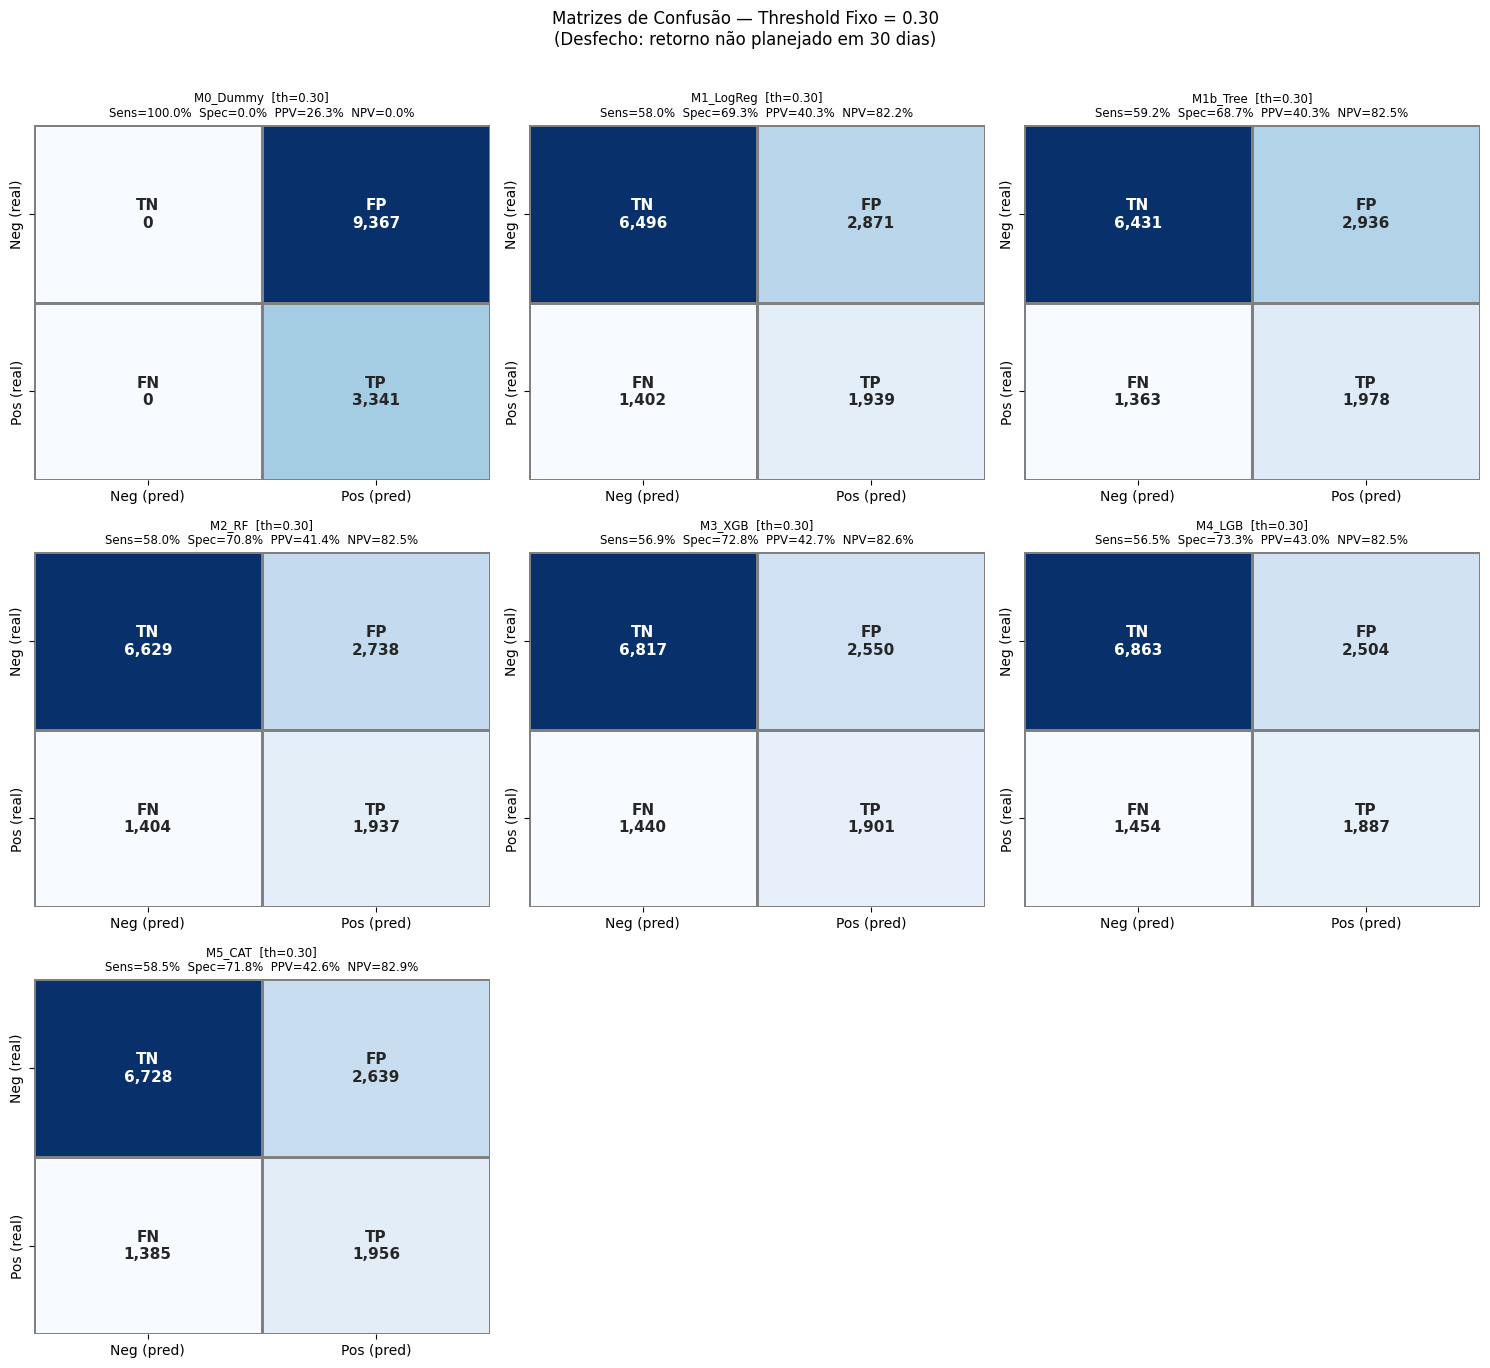

In [19]:
MODELOS_LISTA = list(probs_teste.keys())
NCOLS_CM = 3
NROWS_CM = (len(MODELOS_LISTA) + NCOLS_CM - 1) // NCOLS_CM

fig_cm, axes_cm = plt.subplots(NROWS_CM, NCOLS_CM, figsize=(5 * NCOLS_CM, 4.5 * NROWS_CM))
axes_cm_flat = axes_cm.flatten()

rows_cm_fixo = []
for idx, nome in enumerate(MODELOS_LISTA):
    y_pred = (probs_teste[nome] >= 0.30).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    ppv  = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    npv  = tn / (tn + fn) if (tn + fn) > 0 else 0.0

    ax = axes_cm_flat[idx]
    annot = np.array([[f"TN\n{tn:,}", f"FP\n{fp:,}"],
                      [f"FN\n{fn:,}", f"TP\n{tp:,}"]])
    sns.heatmap(cm, annot=annot, fmt="", ax=ax, cmap="Blues",
                xticklabels=[T["cm_neg_pred"], T["cm_pos_pred"]],
                yticklabels=[T["cm_neg_real"], T["cm_pos_real"]],
                linewidths=0.8, linecolor="gray",
                annot_kws={"size": 11, "weight": "bold"},
                cbar=False)
    ax.set_title(
        f"{nome}  [th=0.30]\n{T['cm_fixo_title_fmt'].format(sens=sens, spec=spec, ppv=ppv, npv=npv)}",
        fontsize=8.5)
    ax.set_xlabel(""); ax.set_ylabel("")

    rows_cm_fixo.append({"modelo": nome, "threshold": 0.30,
                          "TP": int(tp), "FP": int(fp),
                          "FN": int(fn), "TN": int(tn),
                          "sensibilidade": round(sens, 4),
                          "especificidade": round(spec, 4),
                          "PPV": round(ppv, 4),
                          "NPV": round(npv, 4)})

for idx in range(len(MODELOS_LISTA), len(axes_cm_flat)):
    axes_cm_flat[idx].set_visible(False)

plt.suptitle(T["cm_fixo_suptitle"], fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR / "12_confusion_matrix_th_fixo.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close()

df_cm_fixo = pd.DataFrame(rows_cm_fixo)
df_cm_fixo.to_csv(OUT_DIR / "confusion_matrix_th_fixo.csv", index=False)
print("Gerado: plots/12_confusion_matrix_th_fixo.png")
print(df_cm_fixo.to_string(index=False))

## Matrizes de Confusão — Melhor Threshold (Youden)

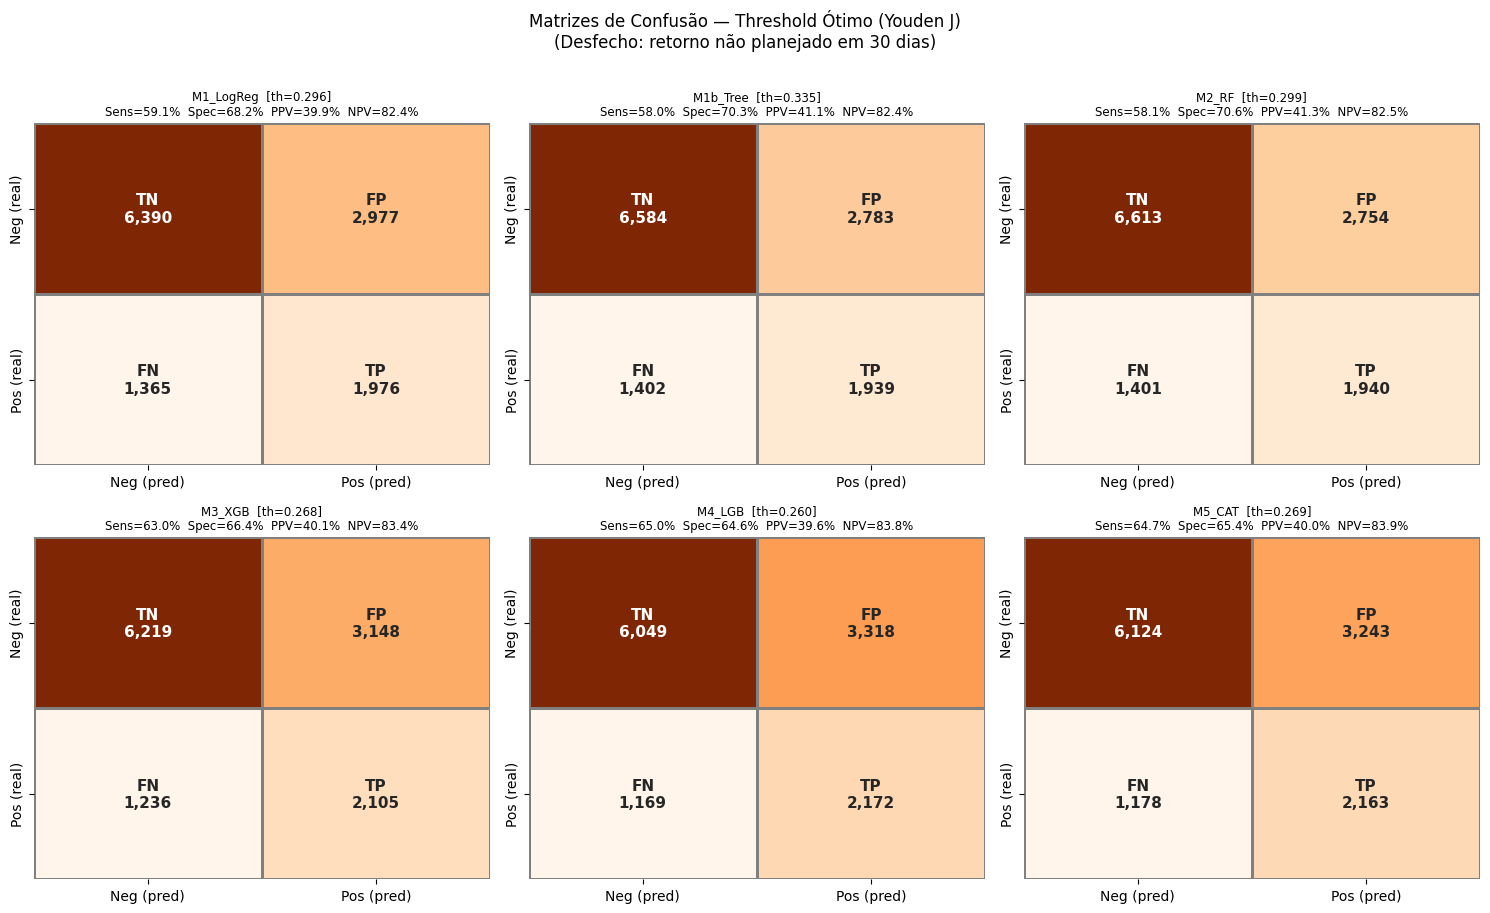

In [20]:
MODELOS_YOUDEN = [m for m in MODELOS_LISTA if threshold_youden_por_modelo.get(m, float("inf")) != float("inf")]
NCOLS_Y = 3
NROWS_Y = (len(MODELOS_YOUDEN) + NCOLS_Y - 1) // NCOLS_Y

fig_y, axes_y = plt.subplots(NROWS_Y, NCOLS_Y, figsize=(5 * NCOLS_Y, 4.5 * NROWS_Y))
axes_y_flat = axes_y.flatten() if NROWS_Y > 1 else np.array(axes_y).flatten()

rows_cm_youden = []
for idx, nome in enumerate(MODELOS_YOUDEN):
    th_y = float(threshold_youden_por_modelo[nome])

    y_pred_y = (probs_teste[nome] >= th_y).astype(int)
    cm_y = confusion_matrix(y_test, y_pred_y)
    tn, fp, fn, tp = cm_y.ravel()

    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    ppv  = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    npv  = tn / (tn + fn) if (tn + fn) > 0 else 0.0

    ax_y = axes_y_flat[idx]
    annot_y = np.array([[f"TN\n{tn:,}", f"FP\n{fp:,}"],
                         [f"FN\n{fn:,}", f"TP\n{tp:,}"]])
    sns.heatmap(cm_y, annot=annot_y, fmt="", ax=ax_y, cmap="Oranges",
                xticklabels=[T["cm_neg_pred"], T["cm_pos_pred"]],
                yticklabels=[T["cm_neg_real"], T["cm_pos_real"]],
                linewidths=0.8, linecolor="gray",
                annot_kws={"size": 11, "weight": "bold"},
                cbar=False)
    ax_y.set_title(
        f"{nome}  [th={th_y:.3f}]\n{T['cm_youden_title_fmt'].format(sens=sens, spec=spec, ppv=ppv, npv=npv)}",
        fontsize=8.5)
    ax_y.set_xlabel(""); ax_y.set_ylabel("")

    rows_cm_youden.append({"modelo": nome, "threshold_youden": round(th_y, 4),
                            "TP": int(tp), "FP": int(fp),
                            "FN": int(fn), "TN": int(tn),
                            "sensibilidade": round(sens, 4),
                            "especificidade": round(spec, 4),
                            "PPV": round(ppv, 4),
                            "NPV": round(npv, 4)})

for idx in range(len(MODELOS_YOUDEN), len(axes_y_flat)):
    axes_y_flat[idx].set_visible(False)

plt.suptitle(T["cm_youden_suptitle"], fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR / "12b_confusion_matrix_th_youden.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close()

df_cm_youden = pd.DataFrame(rows_cm_youden)
df_cm_youden.to_csv(OUT_DIR / "confusion_matrix_th_youden.csv", index=False)
print("Gerado: plots/12b_confusion_matrix_th_youden.png")
print(df_cm_youden.to_string(index=False))

print(f"\n[03.3] Concluído. Outputs: {OUT_DIR}")